[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/01_gmm.py)

# Gaussian Mixture Models: Fitting, Inspecting and Initializing

This is the starting point for `tgmm`. It fits a `GaussianMixture` to a small synthetic 2-D dataset and walks through everything you do with a fitted model: predicting cluster labels and soft assignments, scoring and sampling, inspecting the learned parameters, and plotting them with `plot_gmm`.

It then covers how EM is started (initial means, weights and covariances), the controls on the optimization itself, and short tours of Classification EM, MAP estimation with priors, constrained sampling and model persistence -- each of which has a dedicated tutorial later on.

**What you'll learn**

- Fit a `GaussianMixture` and use `predict`, `predict_proba`, `score_samples` and `sample`
- Inspect `weights_`, `means_` and `covariances_` and visualize them with `plot_gmm`
- Compare initialization strategies for the means, weights and covariances
- Use training controls: `n_init`, `warm_start`, `max_iter`/`tol` and per-call overrides in `fit`
- Get a first look at CEM, MAP priors, constrained sampling, and `save`/`load`

**Prerequisites:** none.

**See also:** the [Gaussian Mixture Model user guide](../user-guide/gaussian-mixture.md) for the underlying equations.

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from tgmm import GaussianMixture, GMMInitializer, dynamic_figsize, plot_gmm, generate_gmm_data

plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; marimo embeds figures at 2x, so keep outputs small
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## Synthetic Data Generation

The synthetic dataset is generated by combining four Gaussian components

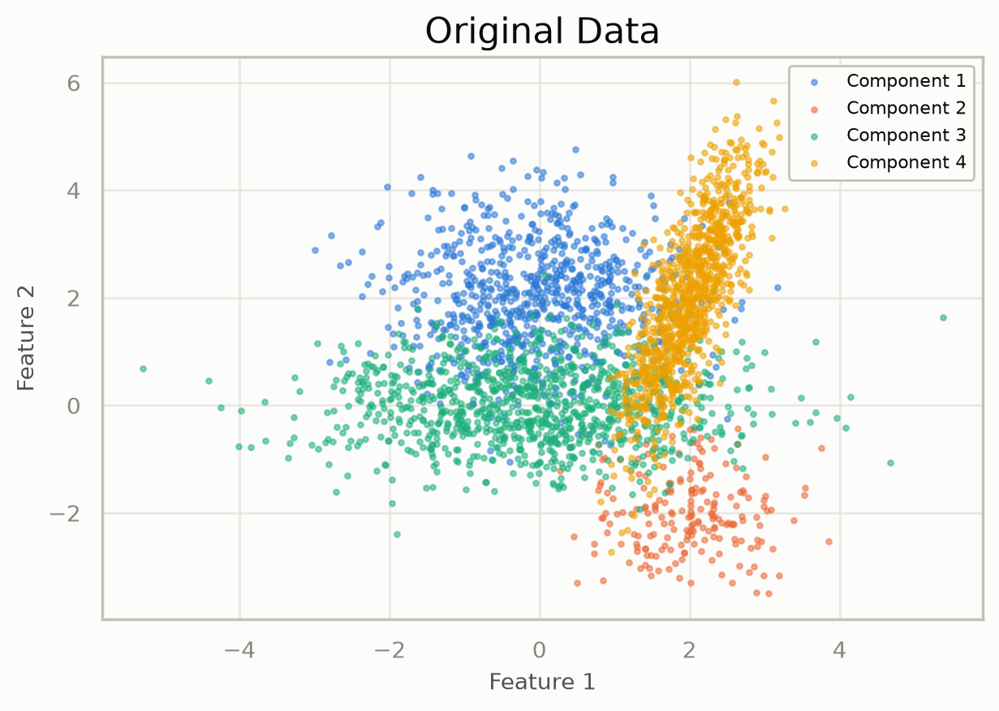

In [ ]:
n_samples = [800, 200, 1000, 1000]
centers = [np.array([0, 2]),
           np.array([2, -2]),
           np.array([0, 0]),
           np.array([2, 2])]
covs = [
    1.0 * np.eye(2),                    # spherical covariance
    0.5 * np.eye(2),                    # spherical covariance, fewer points
    np.array([[2, 0], [0, 0.5]]),       # diagonal covariance
    np.array([[0.2, 0.5], [0.5, 2]])    # full covariance
]

# Generate synthetic data using the new function
_X_tensor, _y_tensor = generate_gmm_data(centers, covs, n_samples, device=device, random_state=SEED)

# Convert to numpy for plotting
X = _X_tensor.cpu().numpy()
labels = _y_tensor.cpu().numpy()
legend_labels = [f'Component {i+1}' for i in range(len(n_samples))]


plot_gmm(X=X, true_labels=labels, title='Original Data', legend_labels=legend_labels)
plt.gcf()

Want to move the blobs and change their covariances? Try the [Design Your Own Mixture explainer](../explainers/data-designer.md) -- it runs in your browser: you choose each blob's position, spread, rotation and number of points, and watch a Gaussian mixture fit it.

## Fitting the GMM

Here we fit a GMM to the data. We choose the number of clusters `n_components` to be the same as the number of Gaussians we defined in the previous section. We choose a random initialisation, i.e. `init_means='random'` and fit the GMM several times (`n_init=2 * N_INIT`, ten restarts by default and one in the fast docs build) in order to make it less likely to land in local minima. We set `verbose=True` and `verbose_interval=10` to see what is happening during the fitting process.

In [ ]:
X_tensor = torch.tensor(X, dtype=torch.float32, device=device)
n_components = len(n_samples)
gmm = GaussianMixture(n_components=n_components, init_means='random', n_init=2 * N_INIT, verbose=True, verbose_interval=100)
gmm.fit(X_tensor)
y_pred = gmm.predict(X_tensor)
log_probs = gmm.score_samples(X_tensor)
probs = gmm.predict_proba(X_tensor)
probs = probs.detach()
n_samples_to_generate = len(X)
gmm_samples, gmm_labels = gmm.sample(n_samples_to_generate)
gmm_samples = gmm_samples.detach().cpu().numpy()
gmm_labels = gmm_labels.detach().cpu().numpy()
generated_probs = gmm.predict_proba(torch.tensor(gmm_samples, dtype=torch.float32).to(device))
generated_probs = generated_probs.detach().cpu().numpy()
print('Mean per-sample log-likelihood:                        ', gmm.score(X_tensor))
print('Mean per-sample log-likelihood (torch.mean(log_probs)):', torch.mean(log_probs).item())
print('Lower bound:                                           ', gmm.lower_bound_)
for _i in range(probs.shape[0]):
    assert np.isclose(torch.sum(probs[_i]).item(), 1.0), f'Probabilities for sample {_i} do not sum to 1'
print('Number of iterations:                                  ', gmm.n_iter_)
print('Converged:                                             ', gmm.converged_)

[Run 1] Iteration 0: log-likelihood=-3.57692
[Run 1] Iteration 63: log-likelihood=-3.38458, Converged!
[Run 2] Iteration 0: log-likelihood=-3.60880
[Run 2] Iteration 21: log-likelihood=-3.38382, Converged!
Mean per-sample log-likelihood:                         -3.383601188659668
Mean per-sample log-likelihood (torch.mean(log_probs)): -3.383601188659668
Lower bound:                                            -3.383601188659668
Number of iterations:                                   21
Converged:                                              True


## Methods of the GMM

The `GaussianMixture` provides the following methods:

- **Predicted Cluster Labels:** Using the `predict` method.
- **Per-Sample Log-Likelihoods:** Using the `score_samples` method.
- **Posterior Probabilities:** For each data sample across all components.
- **New Samples:** Generated from the fitted GMM, along with the corresponding component indices.

Diagnostic information such as mean log-likelihood, convergence status, and number of iterations is printed to verify the model's performance.

## Inspecting the Learned GMM Parameters

After fitting the model, we inspect the parameters learned by the GMM. For each component, the following are printed:

- **Weight:** The mixing proportion for the component.
- **Mean:** The estimated mean of the component.
- **Covariance:** The covariance matrix (or vector/scalar for other types) representing the spread of the component.


Component 1:
Weight:
0.33286476135253906
Mean:
[ 0.80439    -0.04260659]
Covariance:
[[ 1.3927097  -0.8951206 ]
 [-0.89512056  2.0150335 ]]

Component 2:
Weight:
0.31309184432029724
Mean:
[2.0280435 2.1039376]
Covariance:
[[0.18135649 0.4379198 ]
 [0.4379198  1.765623  ]]

Component 3:
Weight:
0.1668631136417389
Mean:
[0.20595329 2.3494382 ]
Covariance:
[[ 1.0997115  -0.12891115]
 [-0.12891115  0.7193627 ]]

Component 4:
Weight:
0.18718025088310242
Mean:
[-0.9375879  0.1538172]
Covariance:
[[1.2023721  0.1011313 ]
 [0.10113131 0.51848763]]


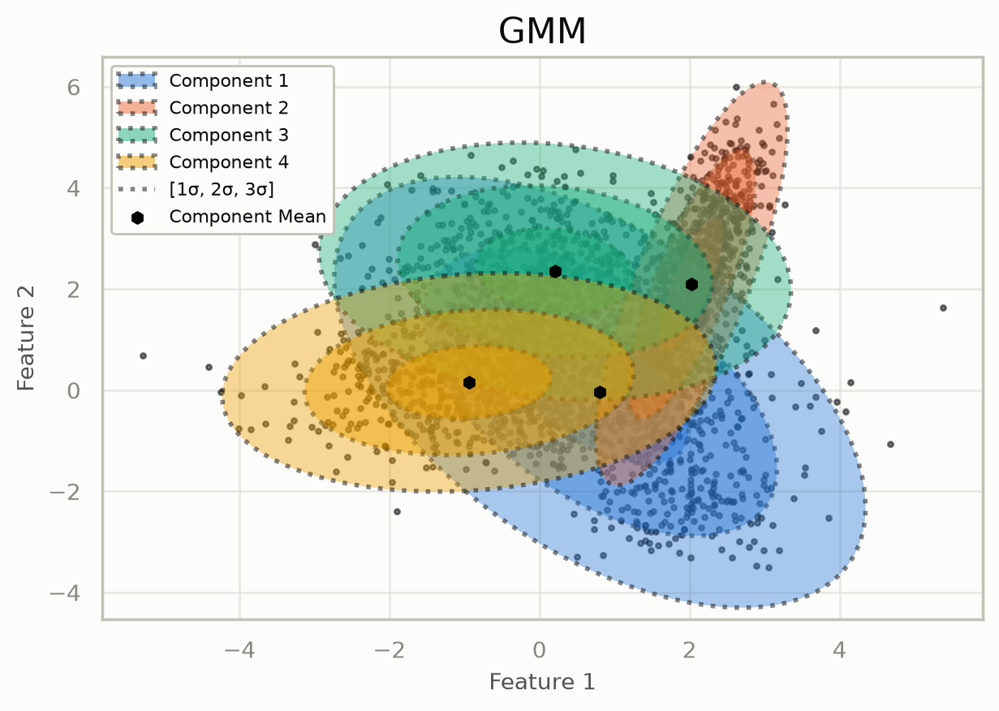

In [ ]:
# weights, means, covariances of each component
for _i in range(gmm.n_components):
    print(f'\nComponent {_i + 1}:')
    print('Weight:')
    print(gmm.weights_[_i].item())
    print('Mean:')
    print(gmm.means_[_i].detach().cpu().numpy())
    print('Covariance:')
    print(gmm.covariances_[_i].detach().cpu().numpy())
plot_gmm(X=X, gmm=gmm, title='GMM', legend_labels=legend_labels)
plt.gcf()

## Visualization of Clustering and Generated Samples

In this section, we visualize several key results using our custom `plot_gmm` function:

1. **Per-Sample Log-Likelihood:**
   A continuous scatter plot where each point is colored by its log-likelihood value. A colorbar is included to indicate the log-likelihood scale.

2. **GMM Clustering Results:**
   A cluster plot where points are colored by their predicted labels. The plot also overlays the final GMM component means and ellipses representing covariance contours.

3. **Generated Samples:**
   The new samples generated by the GMM are plotted along with the model's estimated parameters to evaluate how well the model reproduces the data distribution.

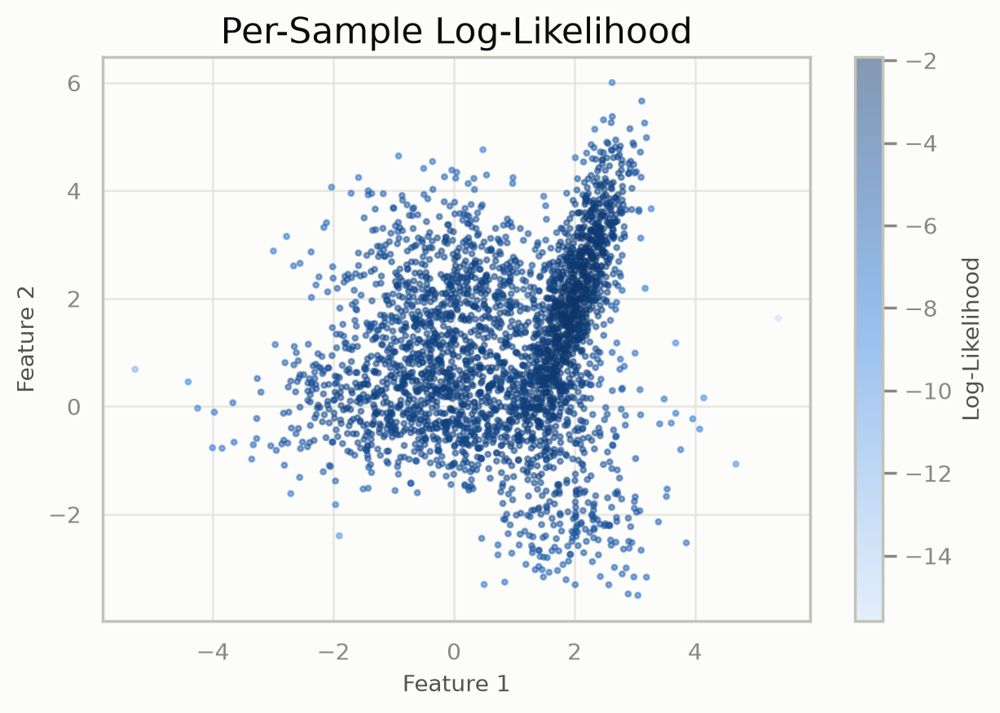

In [ ]:
plot_gmm(X=X, title='Per-Sample Log-Likelihood', log_probs=log_probs, colorbar_label='Log-Likelihood')
plt.gcf()

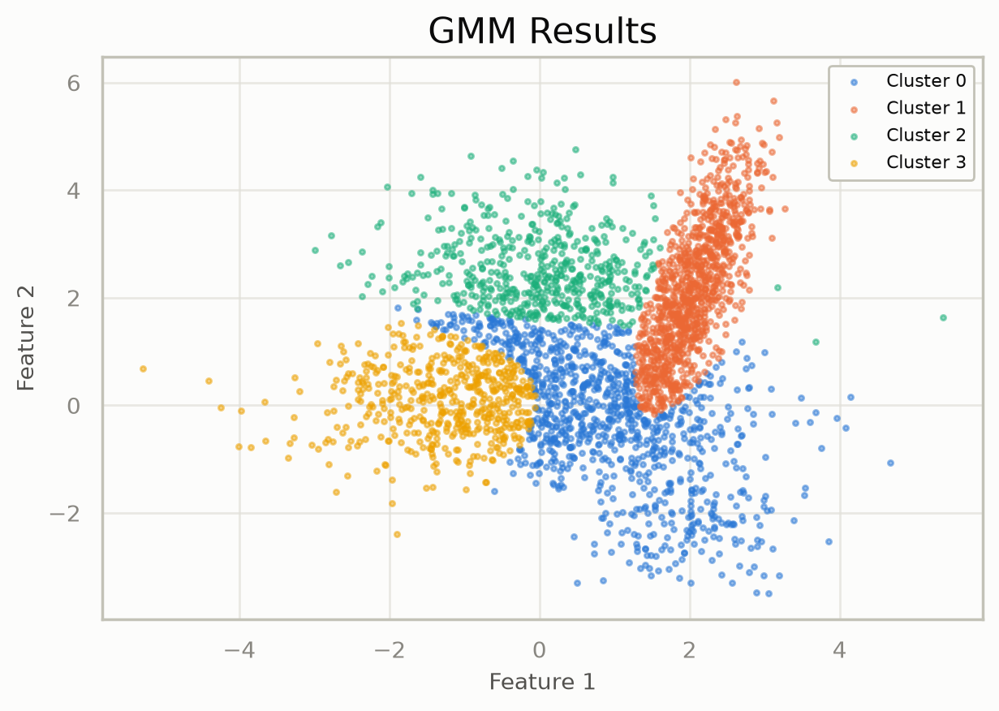

In [ ]:
plot_gmm(X=X, true_labels=y_pred, title='GMM Results', legend_labels=[f'Cluster {i}' for i in range(n_components)])
plt.gcf()

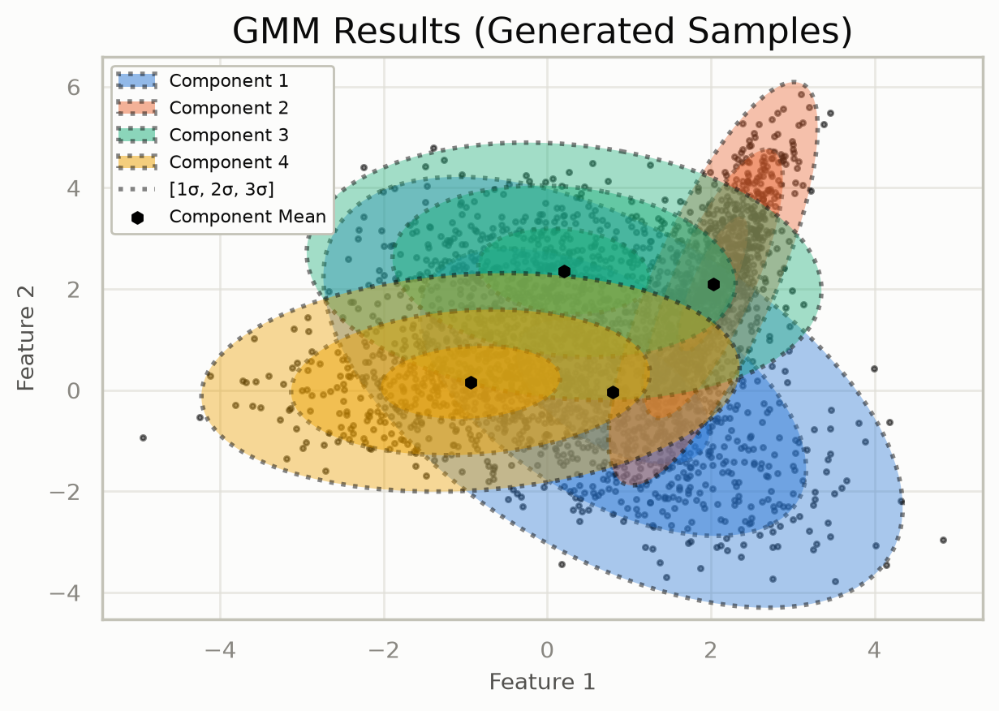

In [ ]:
plot_gmm(X=gmm_samples, gmm=gmm, title='GMM Results (Generated Samples)')
plt.gcf()

## Visualizing Component Probability Distributions

Finally, we analyze the distribution of component responsibilities (i.e., the probability that each sample belongs to a particular component):

- **Observed Data:**
  A grid of subplots is generated where each subplot shows the probability distribution for a single GMM component across the observed data. Each plot uses a continuous color scale (e.g., 'RdBu') with an associated colorbar.

- **Generated Samples:**
  Similarly, we plot the component probability distributions for the generated samples, using a different colormap (e.g., 'PRGn').

These plots provide insight into how the GMM assigns probabilities to each data point and how well each component is represented in both the original and generated data.

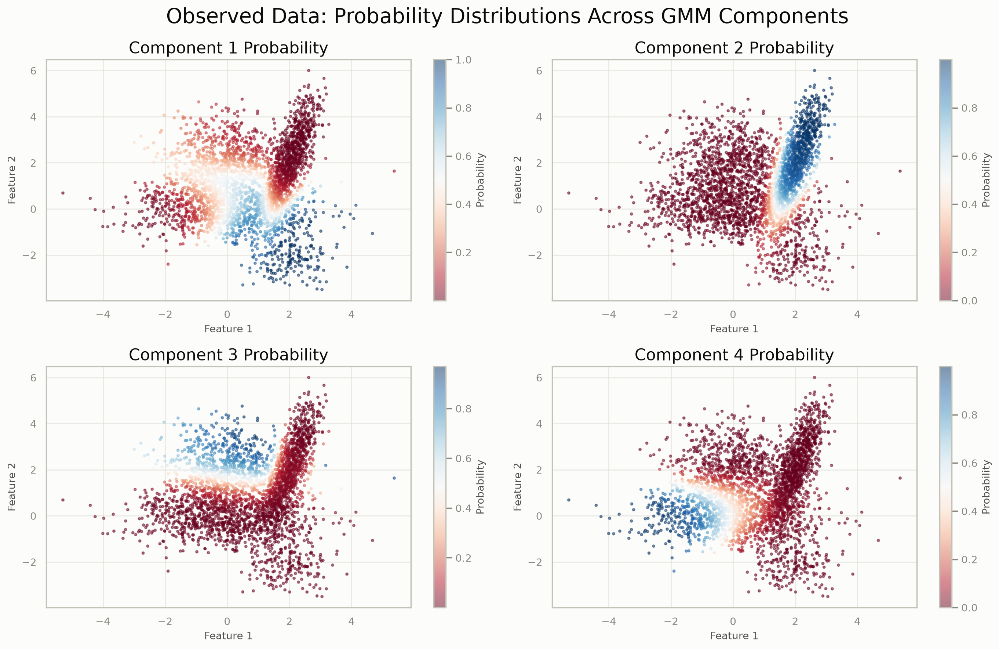

In [ ]:
_fig, _axs = plt.subplots(2, 2, figsize=dynamic_figsize(2, 2))
for _k, _ax in enumerate(_axs.ravel()):
    plot_gmm(X=X, ax=_ax, title=f'Component {_k + 1} Probability', log_probs=probs[:, _k], colormap='RdBu', colorbar_label='Probability')
plt.suptitle('Observed Data: Probability Distributions Across GMM Components')
plt.tight_layout()
plt.gcf()

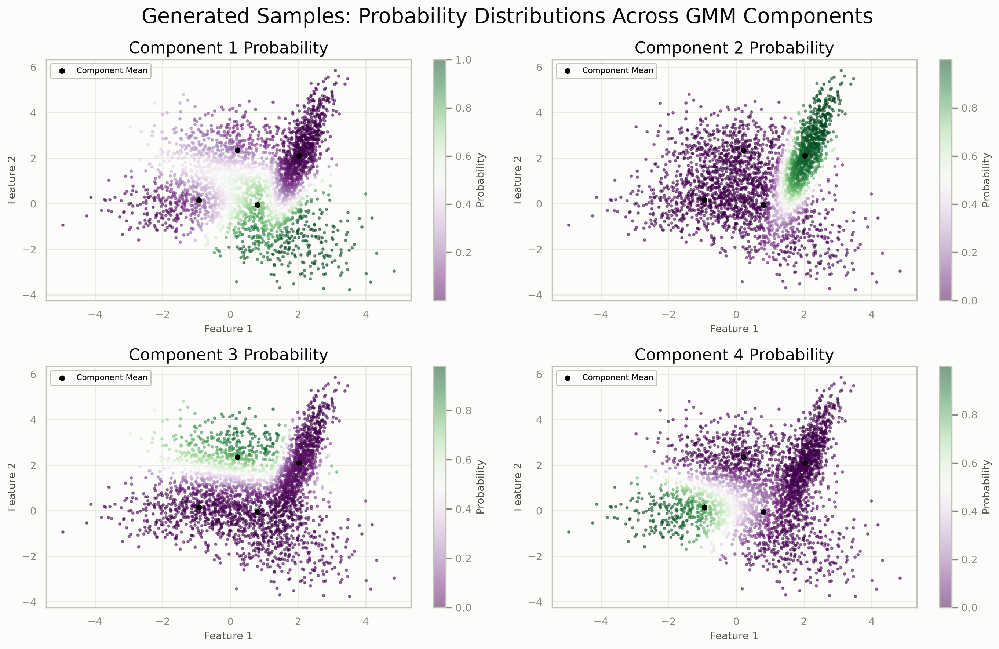

In [ ]:
_fig, _axs = plt.subplots(2, 2, figsize=dynamic_figsize(2, 2))
for _k, _ax in enumerate(_axs.ravel()):
    plot_gmm(X=gmm_samples, gmm=gmm, ax=_ax, show_ellipses=False, title=f'Component {_k + 1} Probability', log_probs=generated_probs[:, _k], colormap='PRGn', colorbar_label='Probability')
_fig.suptitle('Generated Samples: Probability Distributions Across GMM Components')
plt.tight_layout()
plt.gcf()

## Covariance Types

`covariance_type` controls the shape constraints placed on each component's covariance matrix: `'full'` (the default), `'diag'`, `'spherical'`, the three `'tied_*'` variants that share one covariance across components, plus 8 additional parsimonious GPCM models. See [Covariance Structures](15_covariance_models.ipynb) for the math and a visual comparison of all of them, and the [user guide](../user-guide/gaussian-mixture.md) for a reference of the options.

## Comparing Different Initialization Methods

In this section, we investigate how different initialization methods affect the GMM clustering results when using a fixed covariance type (here, **full**). The initialization methods compared are:

- **random**
- **points**
- **kpp** (k-means++)
- **kmeans**
- **maxdist**

Below, we provide a brief mathematical description of each method:

1. **Random Initialization**:
   This method computes the empirical mean $\bar{x} $ and covariance $\Sigma$ of the dataset and then draws each initial center from a Gaussian distribution:
   $$
   \mu_i = \bar{x} + L z, \quad z \sim \mathcal{N}(0, I_d),
   $$
   where $ L $ is the Cholesky factor of $\Sigma$ (i.e. $\Sigma = LL^\top$).
   This yields centers that roughly follow the global data distribution.

2. **Points Initialization**:
   This method simply selects $ k $ points uniformly at random from the dataset. Mathematically, if $ S \subset \{1,2,\dots,N\} $ is a random subset of $ k $ indices, then:
   $$
   \mu_i = x_{s_i}, \quad i = 1, \dots, k.
   $$

3. **k-means++ Initialization (kpp)**:
   The first center is chosen uniformly at random. For each subsequent center, the probability of selecting data point $ x_j $ is proportional to the square of its distance to the nearest already-chosen center:
   $$
   P(x_j) = \frac{D(x_j)}{\sum_{j=1}^{N} D(x_j)}, \quad \text{with } D(x_j) = \min_{l=1,\dots,i-1} \|x_j - \mu_l\|^2.
   $$
   This procedure tends to choose centers that are spread out.

4. **k-means Initialization**:
   Starting from the k-means++ initialization, the standard k-means algorithm is run iteratively:
   - **Assignment step:**
     Assign each point $ x_j $ to the nearest center:
     $$
     c_j = \arg\min_{i} \|x_j - \mu_i\|^2.
     $$
   - **Update step:**
     Recompute each center as the mean of its assigned points:
     $$
     \mu_i = \frac{1}{|C_i|} \sum_{x_j \in C_i} x_j.
     $$
   These steps repeat until convergence (i.e. the centers do not change significantly).

5. **Max-Distance Initialization (maxdist)**:
   This is a modified k-means++ method:
   - The first center is chosen randomly.
   - For $ i = 2,\dots,k $, choose the next center as:
     $$
     \mu_i = \arg\max_{x \in \mathcal{D}} \min_{l=1,\dots,i-1} \|x - \mu_l\|,
     $$
     ensuring that the new center is the point with the largest minimum distance to the existing centers.
   - Finally, the first center is reselected as the point with the largest distance from the centers $ \mu_2,\dots,\mu_k $:
     $$
     \mu_1 = \arg\max_{x \in \mathcal{D}} \min_{l=2,\dots,k} \|x - \mu_l\|.
     $$

For each initialization method, we obtain a set of initial means which are then passed (via the `init_means` parameter) to the GMM. This bypasses the model’s internal initialization logic, allowing us to compare the impact of different starting points on the final clustering.

1. Use a helper function (`get_init_means`) to obtain the initial means from the corresponding method.
2. Initialize a GMM with these precomputed initial means by providing them via the `init_means` parameter (thus bypassing the internal initialization logic).
3. Fit the GMM to the dataset (`X_tensor`).
4. Predict cluster labels and visualize the clustering results with our `plot_gmm` function, which also overlays the initial means (marked in red).

/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:880: UserWarning: Run 1: EM did not converge after 100 iterations.
  warnings.warn(
/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:1303: UserWarning: EM did not converge. Consider increasing max_iter or adjusting tol.
  warnings.warn(
/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:1762: UserWarning: Model did not converge. Results may be unreliable.
  warnings.warn("Model did not converge. Results may be unreliable.", UserWarning)


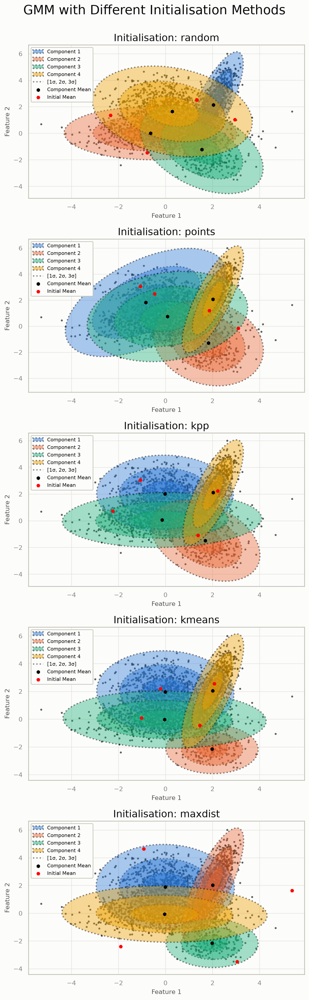

In [ ]:
init_methods = ['random', 'points', 'kpp', 'kmeans', 'maxdist']
torch.manual_seed(SEED)

def get_init_means(method, data, k):
    """
    Returns initial means for a given method from GMMInitializer.
    """
    if method == 'random':
        return GMMInitializer.random(data, k)
    elif method == 'points':
        return GMMInitializer.points(data, k)
    elif method == 'kpp':
        return GMMInitializer.kpp(data, k)
    elif method == 'kmeans':
        return GMMInitializer.kmeans(data, k)
    elif method == 'maxdist':
        return GMMInitializer.maxdist(data, k)
    else:
        raise ValueError(f'Unknown init method: {method}')
_nrows, _ncols = (len(init_methods), 1)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(_nrows, _ncols, figsize=_figsize)
for col_idx, _method in enumerate(init_methods):
    _ax = _axs[col_idx]
    init_means = get_init_means(_method, X_tensor, k=4)
    _gmm = GaussianMixture(n_features=2, n_components=4, covariance_type='full', init_means=init_means, random_state=0, device=device, max_iter=MAX_ITER, tol=1e-06, reg_covar=1e-10)
    _gmm.fit(X_tensor)
    _title = f'Initialisation: {_method}'
    plot_gmm(X, gmm=_gmm, ax=_ax, title=_title, show_initial_means=True, legend_labels=legend_labels)
plt.suptitle('GMM with Different Initialisation Methods')
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.gcf()

## Comparing Different Weight Initialization Methods

In this section, we investigate how different weight initialization methods affect the
starting mixture weights (before EM optimization). The weight initialization methods
compared are:

- **uniform**: Equal weight for every component
- **random**: Sampled from a symmetric Dirichlet distribution
- **kmeans**: Proportional to cluster sizes from a nearest-mean assignment

The initial weights assigned to each component are shown in each panel's title; marker
sizes are scaled by weight (`scale_size_by_weight=True`).

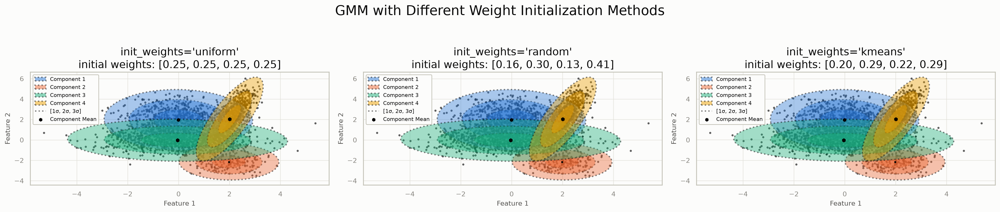

In [ ]:
init_methods_weights = ['uniform', 'random', 'kmeans']
torch.manual_seed(SEED)
_nrows, _ncols = (1, len(init_methods_weights))
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(_nrows, _ncols, figsize=_figsize)
for _ax, _method in zip(_axs, init_methods_weights):
    _gmm = GaussianMixture(n_features=2, n_components=4, covariance_type='full', init_weights=_method, random_state=SEED, device=device, max_iter=MAX_ITER, tol=1e-06, reg_covar=1e-10)
    _gmm.fit(X_tensor)
    weights_str = ', '.join((f'{w:.2f}' for w in _gmm.initial_weights_.cpu().tolist()))
    _title = f"init_weights='{_method}'\ninitial weights: [{weights_str}]"
    plot_gmm(X, gmm=_gmm, ax=_ax, title=_title, legend_labels=legend_labels, scale_size_by_weight=True)
plt.suptitle('GMM with Different Weight Initialization Methods')
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.gcf()

## Comparing Different Covariance Initialization Methods

In this section, we investigate how different covariance initialization methods affect the
GMM's starting ellipses (before EM optimization) and the resulting fit. The covariance
initialization methods compared are:

- **empirical**: Estimated from data assigned to each component by nearest mean (default)
- **eye**: Identity-like matrices, scaled by `1 + reg_covar`
- **random**: Random positive semi-definite matrices
- **global**: The single global covariance of the whole dataset, repeated across components

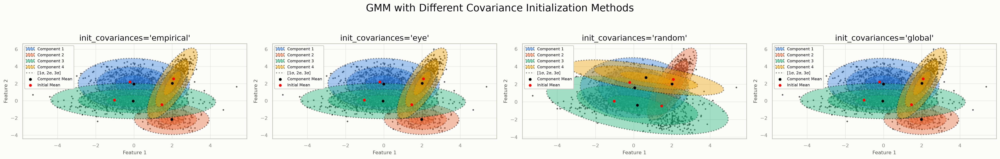

In [ ]:
init_methods_cov = ['empirical', 'eye', 'random', 'global']
torch.manual_seed(SEED)
_nrows, _ncols = (1, len(init_methods_cov))
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axs = plt.subplots(_nrows, _ncols, figsize=_figsize)
for _ax, _method in zip(_axs, init_methods_cov):
    _gmm = GaussianMixture(n_features=2, n_components=4, covariance_type='full', init_covariances=_method, random_state=SEED, device=device, max_iter=MAX_ITER, tol=1e-06, reg_covar=1e-10)
    _gmm.fit(X_tensor)
    _title = f"init_covariances='{_method}'"
    plot_gmm(X, gmm=_gmm, ax=_ax, title=_title, legend_labels=legend_labels, show_initial_means=True)
plt.suptitle('GMM with Different Covariance Initialization Methods')
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.gcf()

## Training Controls

Beyond covariance type and initialization strategy, a few parameters control the EM
optimization itself:

- `max_iter`, `tol`: stop after this many iterations, or once the relative log-likelihood
  improvement drops below `tol`.
- `reg_covar`: regularization added to the covariance diagonal, needed to avoid
  singular/degenerate covariances.
- `n_init`: run EM from this many independent random initializations and keep the best
  (highest log-likelihood) one; the winning seed is stored in `best_random_state_`.
- `warm_start`: reuse the previous fit's parameters as the starting point for the next call to
  `fit`, instead of re-initializing.
- `random_state`: seed for reproducibility. With `n_init > 1`, initialization `i` uses
  `random_state + i`.

`max_iter`, `tol`, `random_state`, and `warm_start` can also be overridden on a single call to
`fit(...)`, without changing the model's own defaults.

In [ ]:
# n_init keeps the best of several random restarts, and records which seed won
gmm_multi = GaussianMixture(n_components=4, n_init=N_INIT, random_state=0, max_iter=200)
gmm_multi.fit(X_tensor)
print(f'Best log-likelihood: {gmm_multi.lower_bound_:.4f}')
print(f'Winning SEED: {gmm_multi.best_random_state_}')
gmm_warm = GaussianMixture(n_components=4, warm_start=True, max_iter=5, random_state=0)
# warm_start: continue optimizing an already-fitted model instead of restarting from scratch
gmm_warm.fit(X_tensor)
print(f'\nAfter 5 iterations: log-likelihood={gmm_warm.lower_bound_:.4f}, converged={gmm_warm.converged_}')
gmm_warm.fit(X_tensor)
print(f'After 5 more (warm-started) iterations: log-likelihood={gmm_warm.lower_bound_:.4f}, converged={gmm_warm.converged_}')  # picks up where it left off instead of re-initializing
gmm_override = GaussianMixture(n_components=4, max_iter=1000, random_state=0)
gmm_override.fit(X_tensor, max_iter=10, tol=0.01)
# fit() accepts overrides for max_iter/tol/SEED/warm_start without touching the model's own defaults
print(f'\nOverridden fit (max_iter=10, tol=1e-2): n_iter_={gmm_override.n_iter_}, converged={gmm_override.converged_}')

Best log-likelihood: -3.3798
Winning SEED: 0


/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:880: UserWarning: Run 1: EM did not converge after 5 iterations.
  warnings.warn(
/home/runner/work/tgmm/tgmm/tgmm/mixtures/base.py:1303: UserWarning: EM did not converge. Consider increasing max_iter or adjusting tol.
  warnings.warn(



After 5 iterations: log-likelihood=-3.3817, converged=False
After 5 more (warm-started) iterations: log-likelihood=-3.3798, converged=True

Overridden fit (max_iter=10, tol=1e-2): n_iter_=2, converged=True


## Custom (Tensor) Initialization

`init_means`, `init_weights`, and `init_covariances` each also accept an explicit
`torch.Tensor` instead of a method name, letting you seed the model with domain knowledge --
for example the output of `GMMInitializer`'s static methods (see the
[GMM Initializer guide](../user-guide/gmm-initializer.md)), a previous run's fitted
parameters, or prior expertise about the data.

In [ ]:
custom_means = torch.tensor([[-1.0, 5.0], [0.0, 5.0], [1.0, 5.0], [2.0, 5.0]])
custom_weights = torch.tensor([0.4, 0.2, 0.2, 0.2])
custom_covs = torch.stack([torch.eye(2) for _ in range(4)])
gmm_custom = GaussianMixture(n_components=4, covariance_type='full', init_means=custom_means, init_weights=custom_weights, init_covariances=custom_covs, random_state=0)
gmm_custom.fit(X_tensor)
print(f'Converged: {gmm_custom.converged_}, log-likelihood={gmm_custom.lower_bound_:.4f}')
print(f'Initial weights (as provided): {gmm_custom.initial_weights_}')

Converged: True, log-likelihood=-3.3992
Initial weights (as provided): tensor([0.4000, 0.2000, 0.2000, 0.2000])


## Classification EM (CEM)

Setting `algorithm='cem'` swaps the soft E-step for a hard classification step between the E-step and
M-step: each point is assigned entirely to its most likely component instead of a probability
distribution over components. This can converge faster, at the cost of being more sensitive to
initialization. See the [CEM tutorial](04_cem.ipynb) for a deeper comparison against standard EM.

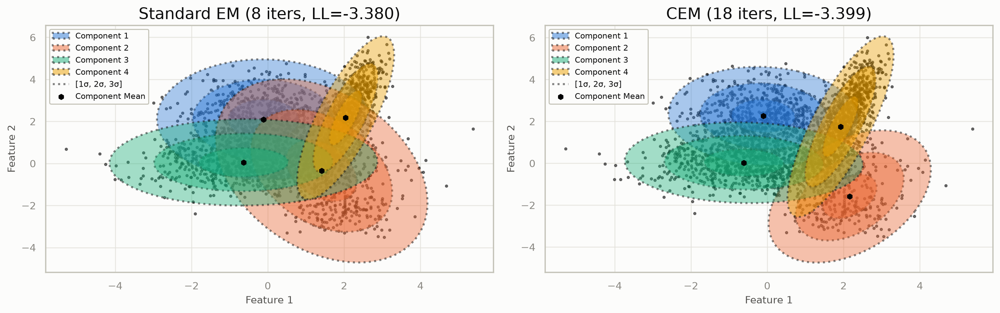

In [ ]:
gmm_em = GaussianMixture(n_components=4, covariance_type='full', random_state=0, max_iter=200)
gmm_em.fit(X_tensor)
gmm_cem = GaussianMixture(n_components=4, covariance_type='full', algorithm='cem', random_state=0, max_iter=200)
gmm_cem.fit(X_tensor)
_fig, _axes = plt.subplots(1, 2, figsize=dynamic_figsize(1, 2))
plot_gmm(X, gmm=gmm_em, ax=_axes[0], title=f'Standard EM ({gmm_em.n_iter_} iters, LL={gmm_em.lower_bound_:.3f})', legend_labels=legend_labels)
plot_gmm(X, gmm=gmm_cem, ax=_axes[1], title=f'CEM ({gmm_cem.n_iter_} iters, LL={gmm_cem.lower_bound_:.3f})', legend_labels=legend_labels)
plt.tight_layout()
plt.gcf()

## MAP Estimation with Priors

Each of `weight_concentration_prior` (Dirichlet), `mean_prior` + `mean_precision_prior`
(Gaussian), and `covariance_prior` + `degrees_of_freedom_prior` (Inverse-Wishart) turns the
corresponding M-step update from a maximum-likelihood estimate into a maximum a posteriori one,
regularizing it toward the prior. When both the mean and covariance priors are supplied, `tgmm`
uses their Normal-Inverse-Wishart (NIW) conjugate joint update instead of independent ones. See
the [Priors tutorial](09_priors.ipynb) and [NIW Priors Comparison](10_niw_priors_comparison.ipynb) for
a deeper dive.

Converged: True, log-likelihood=-3.3797


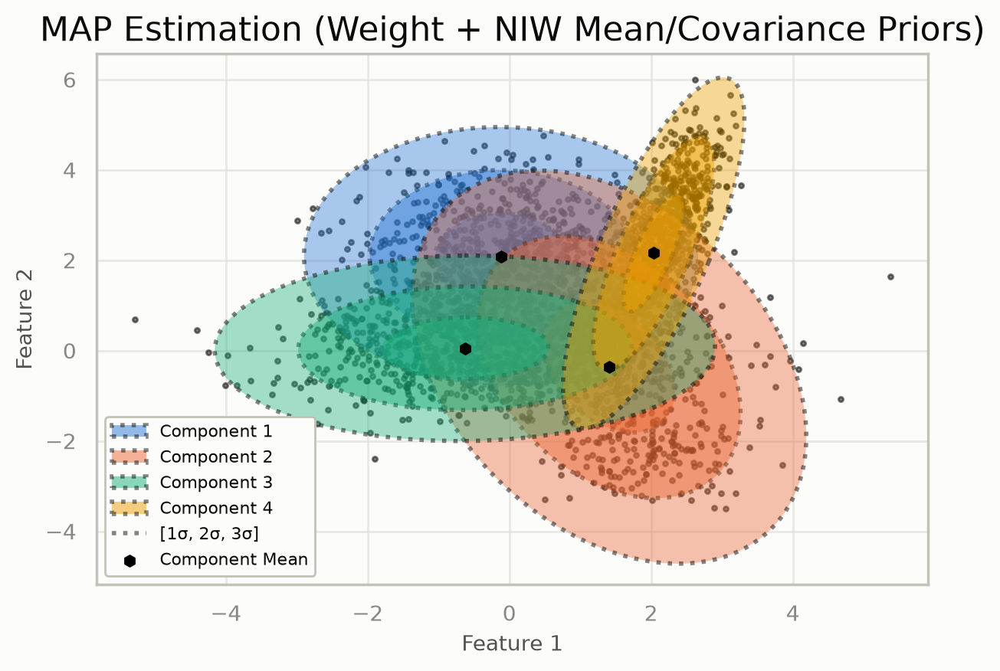

In [ ]:
gmm_map = GaussianMixture(n_components=4, n_features=2, covariance_type='full', weight_concentration_prior=torch.ones(4) * 2.0, mean_prior=torch.zeros(4, 2), mean_precision_prior=0.1, covariance_prior=torch.eye(2).unsqueeze(0).repeat(4, 1, 1), degrees_of_freedom_prior=3.0, random_state=0)
gmm_map.fit(X_tensor)
print(f'Converged: {gmm_map.converged_}, log-likelihood={gmm_map.lower_bound_:.4f}')
_fig, _ax = plt.subplots()
plot_gmm(X, gmm=gmm_map, ax=_ax, title='MAP Estimation (Weight + NIW Mean/Covariance Priors)', legend_labels=legend_labels)
plt.gcf()

## Constrained Sampling

`sample()` supports rejection-sampling constraints beyond plain unconstrained sampling:
sampling only from a specific `component`, within a `std_radius` (Mahalanobis distance) or
`std_range`, within a `confidence`/`confidence_range` region (converted internally via the
$\chi^2$ distribution), or within `center_radius` of a `center_point`. See the
[Sampling tutorial](07_sampling.ipynb) for the full set of options.

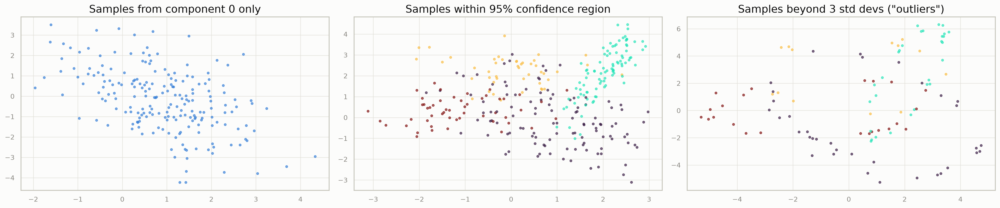

In [ ]:
samples_c0, _ = gmm.sample(200, component=0)
samples_95, labels_95 = gmm.sample(300, confidence=0.95)
samples_outliers, labels_outliers = gmm.sample(100, std_range=(3.0, float('inf')))
_fig, _axes = plt.subplots(1, 3, figsize=dynamic_figsize(1, 3))
_axes[0].scatter(samples_c0[:, 0].cpu(), samples_c0[:, 1].cpu(), s=10, alpha=0.6)
_axes[0].set_title('Samples from component 0 only')
_axes[1].scatter(samples_95[:, 0].cpu(), samples_95[:, 1].cpu(), c=labels_95.cpu(), cmap='turbo', s=10, alpha=0.6)
_axes[1].set_title('Samples within 95% confidence region')
_axes[2].scatter(samples_outliers[:, 0].cpu(), samples_outliers[:, 1].cpu(), c=labels_outliers.cpu(), cmap='turbo', s=10, alpha=0.6)
_axes[2].set_title('Samples beyond 3 std devs ("outliers")')
plt.tight_layout()
plt.gcf()

## Model Saving and Loading

This section demonstrates the save/load functionality for GMM models. The `GaussianMixture` class provides four methods for model persistence:

1. **`save(filepath)`**: Save the complete model (parameters + configuration) to a file
2. **`load(filepath, device=None)`**: Class method to load a complete model from a file
3. **`save_state_dict()`**: Return a dictionary containing all model state (similar to PyTorch)
4. **`load_state_dict(state_dict)`**: Load model state from a dictionary

These methods preserve all model parameters, configuration settings, training state, and prior settings, allowing for complete model reproducibility.

In [ ]:
import os
import tempfile
print('Original model info:')
# Use the previously fitted GMM (gmm) from earlier cells
print(f'  Number of components: {gmm.n_components}')
print(f'  Covariance type: {gmm.covariance_type}')
print(f'  Converged: {gmm.converged_}')
print(f'  Number of iterations: {gmm.n_iter_}')
print(f'  Log-likelihood: {gmm.score(X_tensor):.4f}')
print(f'  Component weights: {gmm.weights_.detach().cpu().numpy()}')
print()
print('=== Method 1: Complete Model Save/Load ===')
with tempfile.NamedTemporaryFile(suffix='.pth', delete=False) as f:
# ========================================
# Method 1: Complete model save/load
    model_path = f.name
gmm.save(model_path)
print(f'Model saved to: {model_path}')
# Save the complete model
loadedgmm = GaussianMixture.load(model_path, device=device)
print('Model loaded successfully!')
print('Loaded model info:')
print(f'  Number of components: {loadedgmm.n_components}')
print(f'  Covariance type: {loadedgmm.covariance_type}')
print(f'  Converged: {loadedgmm.converged_}')
# Load the complete model
print(f'  Number of iterations: {loadedgmm.n_iter_}')
print(f'  Log-likelihood: {loadedgmm.score(X_tensor):.4f}')
print(f'  Component weights: {loadedgmm.weights_.detach().cpu().numpy()}')
# Verify the loaded model
original_predictions = gmm.predict(X_tensor)
loaded_predictions = loadedgmm.predict(X_tensor)
predictions_match = torch.equal(original_predictions, loaded_predictions)
print(f'  Predictions match: {predictions_match}')
os.unlink(model_path)
print()
print('=== Method 2: State Dictionary Save/Load ===')
state_dict = gmm.save_state_dict()
# Test that predictions are identical
print(f'State dict contains {len(state_dict)} keys:')
for key in list(state_dict.keys())[:10]:
    print(f'  {key}')
if len(state_dict) > 10:
    print(f'  ... and {len(state_dict) - 10} more')
# Clean up
print()
newgmm = GaussianMixture(n_components=4, n_features=2, device=device)
newgmm.load_state_dict(state_dict)
print('State dict loaded into new model!')
# Method 2: State dictionary save/load
print('New model info:')
print(f'  Number of components: {newgmm.n_components}')
print(f'  Covariance type: {newgmm.covariance_type}')
# Get state dictionary
print(f'  Converged: {newgmm.converged_}')
print(f'  Number of iterations: {newgmm.n_iter_}')
print(f'  Log-likelihood: {newgmm.score(X_tensor):.4f}')  # Show first 10 keys
print(f'  Component weights: {newgmm.weights_.detach().cpu().numpy()}')
new_predictions = newgmm.predict(X_tensor)
predictions_match = torch.equal(original_predictions, new_predictions)
print(f'  Predictions match original: {predictions_match}')
print()
# Create a new model and load the state
print('=== Practical Example: Training and Persistence Workflow ===')
subset_size = 1000  # Must match the saved model
X_subset = X_tensor[:subset_size]  # Must match the saved model
quickgmm = GaussianMixture(n_components=3, covariance_type='diag', max_iter=100, verbose=False, device=device)
quickgmm.fit(X_subset)
print(f'Quick model trained:')
print(f'  Iterations: {quickgmm.n_iter_}')
print(f'  Log-likelihood: {quickgmm.score(X_subset):.4f}')
with tempfile.NamedTemporaryFile(suffix='.pth', delete=False) as f:
# Verify the new model
    quick_model_path = f.name
quickgmm.save(quick_model_path)
del quickgmm
restoredgmm = GaussianMixture.load(quick_model_path, device=device)
print(f'Model restored from file:')
print(f'  Iterations: {restoredgmm.n_iter_}')
print(f'  Log-likelihood on subset: {restoredgmm.score(X_subset):.4f}')
print(f'  Log-likelihood on full data: {restoredgmm.score(X_tensor):.4f}')
# Test predictions
restored_samples, _ = restoredgmm.sample(200)
print(f'Generated {len(restored_samples)} samples from restored model')
os.unlink(quick_model_path)
print('\n=== Summary ===')
print('✓ Complete model save/load preserves all parameters and configuration')
print('✓ State dictionary methods provide PyTorch-style flexibility')
# Demonstration: Model persistence workflow
print('✓ All training state (convergence, iterations, likelihood) is preserved')
# Train a new model on subset of data
# Save using temporary file for demonstration
# Simulate loading in a different session
# Load and continue working
# Generate samples from restored model
print('✓ Models can be saved, loaded, and used for inference seamlessly')  # Simulate model going out of scope

Original model info:
  Number of components: 4
  Covariance type: full
  Converged: True
  Number of iterations: 21
  Log-likelihood: -3.3836
  Component weights: [0.33286476 0.31309184 0.16686311 0.18718025]

=== Method 1: Complete Model Save/Load ===
Model saved to: /tmp/tmp1ky_24qe.pth
Model loaded successfully!
Loaded model info:
  Number of components: 4
  Covariance type: full
  Converged: True
  Number of iterations: 21
  Log-likelihood: -3.3836
  Component weights: [0.33286476 0.31309184 0.16686311 0.18718025]
  Predictions match: True

=== Method 2: State Dictionary Save/Load ===
State dict contains 66 keys:
  weights_
  means_
  covariances_
  volume_
  shape_
  orientation_
  initial_weights_
  initial_means_
  initial_covariances_
  n_components
  ... and 56 more

State dict loaded into new model!
New model info:
  Number of components: 4
  Covariance type: full
  Converged: True
  Number of iterations: 21
  Log-likelihood: -3.3836
  Component weights: [0.33286476 0.3130918

## Summary

- `GaussianMixture(n_components=K).fit(X)` is all that is needed for a first fit; `predict`, `predict_proba`, `score_samples` and `sample` give hard labels, soft assignments, per-point log-likelihoods and new data.
- `plotgmm` overlays the fitted means and covariance ellipses on the data and can color points by cluster, responsibility or log-likelihood.
- Initialization matters: `init_means`, `init_weights` and `init_covariances` each accept a named strategy or an explicit tensor, and `n_init` restarts guard against poor local optima.
- `max_iter`, `tol`, `reg_covar`, `warm_start` and `random_state` control the optimization and can be overridden per `fit` call.
- `algorithm='cem'`, MAP priors, constrained sampling and `save`/`load` are each covered in more depth in later tutorials.

**Next:** [02 -- EM Algorithm Walkthrough](02_em_algorithm.ipynb) for what happens inside `fit`, then [03 -- Visualization](03_visualise.ipynb) and [15 -- Covariance Structures](15_covariance_models.ipynb).